# Hierarchical detection and tracking: a synthetic walkthrough

This notebook explains **how the algorithm works** on a small synthetic scene where every object is known in advance. No simulation file is needed.

We declare a *family* of four levels:

```
cloud              root          MRC + MRI > 0.05 g/kg
├── updraft        child         W > 1 m/s,  searched inside each cloud
│   └── core       grandchild    W > 3 m/s,  searched inside each updraft, split on the W maxima
└── downdraft      child         W < -1 m/s, searched inside each cloud
```

Then we show what the hierarchy brings compared with detecting each level on its own.

What comes from `src/tracking` and what you write yourself:

| You write | The library provides |
|---|---|
| one **rule** per level (a dict: thresholds, size filters, optional split) | the generic detector `detect_objects` |
| the **hierarchy** (`parent_name` of each level) | the engine `HierarchicalTrackingEngine` |
| the **tracker settings** of each level | the tracker `AdvectedIoUTracker` |

In [1]:
%matplotlib inline
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo_root))

from examples.plot_synthetic import STYLE, draw_objects, legend, plot_scene, plot_step
from examples.synthetic_data import DT_S, DX_KM, make_frames
from src.tracking import AdvectedIoUTracker, HierarchicalTrackingEngine, TrackingLevel, detect_objects

## 1. The synthetic scene

`make_frames` builds 8 snapshots, 5 min apart, of a 100 × 60 km domain with 20 levels (0 to 10 km). Each snapshot is an `xarray.Dataset` with `W` (vertical velocity), `MRC` and `MRI` (cloud water and ice), exactly like one timestep of a MesoNH output.

- **Cloud A** drifts eastward. It holds one broad updraft with **two cores** that move towards each other and **merge** around 12:15, and a **downdraft** on its western flank.
- **Cloud B** is static, with one updraft and one core.
- A **dry thermal** (strong W, no hydrometeors) sits south of cloud B. It is a trap: it looks like a core, but it is not in a cloud.

In [2]:
frames, time_values, timestamps_s = make_frames(n_times=8)
print(f"{len(frames)} timesteps: {time_values}")
frames[0]

8 timesteps: ['12:00', '12:05', '12:10', '12:15', '12:20', '12:25', '12:30', '12:35']


<xarray.Dataset> Size: 1MB
Dimensions:  (level: 20, y: 60, x: 100, level_w: 20)
Coordinates:
  * level    (level) float64 160B 250.0 750.0 1.25e+03 ... 9.25e+03 9.75e+03
  * level_w  (level_w) float64 160B 0.0 500.0 1e+03 ... 8.5e+03 9e+03 9.5e+03
Dimensions without coordinates: y, x
Data variables:
    W        (level, y, x) float32 480kB 2.789e-20 4.393e-20 ... 7.261e-35
    MRC      (level, y, x) float32 480kB 6.701e-07 8.872e-07 ... 0.0 0.0
    MRI      (level, y, x) float32 480kB 0.0 0.0 0.0 ... 2.187e-13 9.777e-14

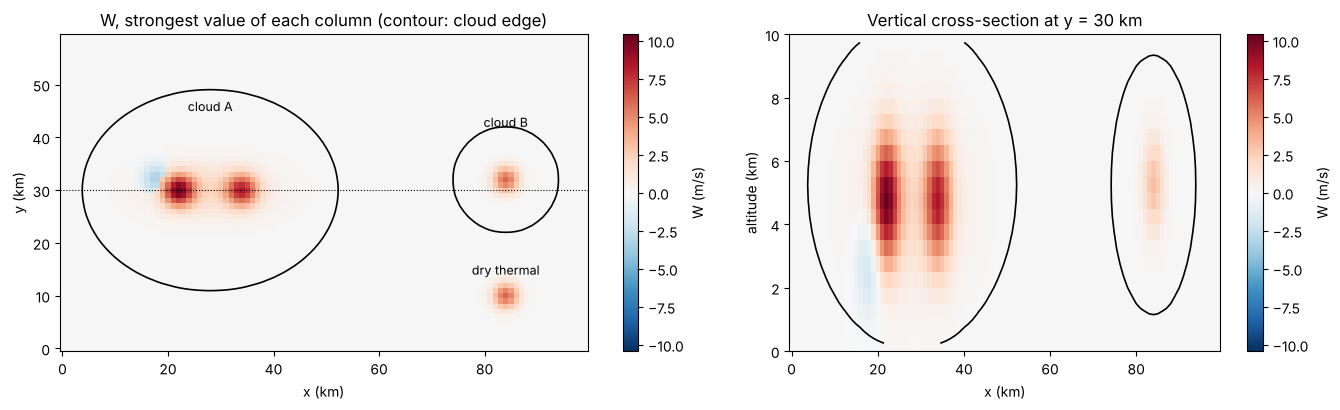

In [3]:
plot_scene(frames[0])

## 2. One rule per level

A rule says **what an object is**, nothing more. The detector applies it in four steps:

1. **mask**: all the `conditions` combined with AND (several variables in one condition are summed first, here `MRC + MRI`);
2. **objects**: 3D connected components of the mask;
3. **split** (optional): each component is cut along the maxima of a variable (recursive H-maxima watershed); this is how one updraft gives several cores;
4. **size filters**: `min_voxels`, `min_area_px`, `min_width_px`, `min_area_km2`.

The rules do not mention the hierarchy: the same `core` rule could be used at the root.

In [4]:
GRID = {"dx_km": DX_KM}  # no vertical clipping: the whole 0-10 km column is used

RULES = {
    "cloud": {
        **GRID,
        "conditions": [{"variables": ["MRC", "MRI"], "op": ">", "value": 0.05}],
        "min_voxels": 50,
    },
    "updraft": {
        **GRID,
        "conditions": [{"variables": "W", "op": ">", "value": 1.0}],
        "min_voxels": 20,
    },
    "downdraft": {
        **GRID,
        "conditions": [{"variables": "W", "op": "<", "value": -1.0}],
        "min_voxels": 20,
    },
    "core": {
        **GRID,
        "conditions": [{"variables": "W", "op": ">", "value": 3.0}],
        "split": "W",          # cut along the maxima of W
        "min_voxels": 10,
    },
}

## 3. Declaring the hierarchy

A `TrackingLevel` joins a name, a detector, a rule, a **parent** and, optionally, a tracker. The hierarchy is nothing more than the `parent_name` of each level:

- a **root** level (`parent_name=None`) is searched once over the whole domain;
- a **child** level is searched **once per parent object, inside that parent's voxels only**.

Levels are listed parents first (the engine checks it). `updraft` and `downdraft` are siblings: both are searched in the clouds, independently of each other.

Each level gets its own tracker. `max_speed_ms=30` bounds the search radius: a track can only be continued by an object whose centroid is within 30 m/s × 300 s = 9 km of its predicted position.

In [5]:
def tracker(name):
    return AdvectedIoUTracker(name, min_score=0.1, patience=1, dx_meters=DX_KM * 1000.0, max_speed_ms=30.0)


levels = [
    TrackingLevel("cloud",     detect_objects, parent_name=None,      params=RULES["cloud"],     tracker=tracker("cloud")),
    TrackingLevel("updraft",   detect_objects, parent_name="cloud",   params=RULES["updraft"],   tracker=tracker("updraft")),
    TrackingLevel("downdraft", detect_objects, parent_name="cloud",   params=RULES["downdraft"], tracker=tracker("downdraft")),
    TrackingLevel("core",      detect_objects, parent_name="updraft", params=RULES["core"],      tracker=tracker("core")),
]
level_names = [lvl.name for lvl in levels]
engine = HierarchicalTrackingEngine(levels)

## 4. Detection and tracking

`run_and_track` detects every level at every timestep, then feeds each tracker in chronological order.

In [6]:
out = engine.run_and_track(frames, time_values=time_values, timestamps_s=timestamps_s)
results, tracks = out["results_by_time"], out["tracks_by_level"]

pd.DataFrame(
    {name: [len(step["levels"][name]) for step in results] for name in level_names},
    index=pd.Index(time_values, name="time"),
)

,cloud,updraft,downdraft,core
time,,,,
12:00,2,2,1,3
12:05,2,2,1,3
12:10,2,2,1,3
12:15,2,2,1,2
12:20,2,2,1,2
12:25,2,2,1,2
12:30,2,2,1,2
12:35,2,2,1,2


Two clouds, two updrafts and one downdraft at every timestep, as built. The number of cores drops from 3 to 2 at 12:15: the two cores of cloud A have merged.

### What an object looks like

An object is a plain `dict`. The detector gives its **geometry** (`indices_3d` = the `(z, y, x)` of its voxels, size, centroid); the engine adds `level`, `object_id` and, for a child only, **`parent_object_id`** (root objects have none).

In [7]:
step0 = results[0]
pd.DataFrame(
    [{k: o.get(k) for k in ("level", "object_id", "parent_object_id", "volume_km3", "height_km", "centroid_x", "centroid_y")}
     for name in level_names for o in step0["levels"][name]]
).fillna({"parent_object_id": "-"}).round(1)

,level,object_id,parent_object_id,volume_km3,height_km,centroid_x,centroid_y
0,cloud,t12:00_cloud_0001,-,9998.0,10.0,28.0,30.0
1,cloud,t12:00_cloud_0002,-,1724.5,8.5,84.0,32.0
2,updraft,t12:00_updraft_0001,t12:00_cloud_0001,777.0,6.5,28.1,29.9
3,updraft,t12:00_updraft_0002,t12:00_cloud_0002,94.5,4.5,84.0,32.0
4,downdraft,t12:00_downdraft_0001,t12:00_cloud_0001,53.0,3.0,17.5,32.4
5,core,t12:00_core_0001,t12:00_updraft_0001,131.5,4.5,22.4,30.0
6,core,t12:00_core_0002,t12:00_updraft_0001,113.0,4.5,33.8,30.0
7,core,t12:00_core_0003,t12:00_updraft_0002,20.5,2.5,84.0,32.0


The detector does not compute physical quantities on purpose: you get them from `indices_3d`. For instance, the peak vertical velocity of each core:

In [8]:
w0 = frames[0]["W"].values
for core in step0["levels"]["core"]:
    idx = core["indices_3d"]
    print(f"{core['object_id']}: {len(idx):4d} voxels, W max = {w0[tuple(idx.T)].max():.1f} m/s")

t12:00_core_0001:  263 voxels, W max = 10.4 m/s
t12:00_core_0002:  226 voxels, W max = 8.5 m/s
t12:00_core_0003:   41 voxels, W max = 6.0 m/s


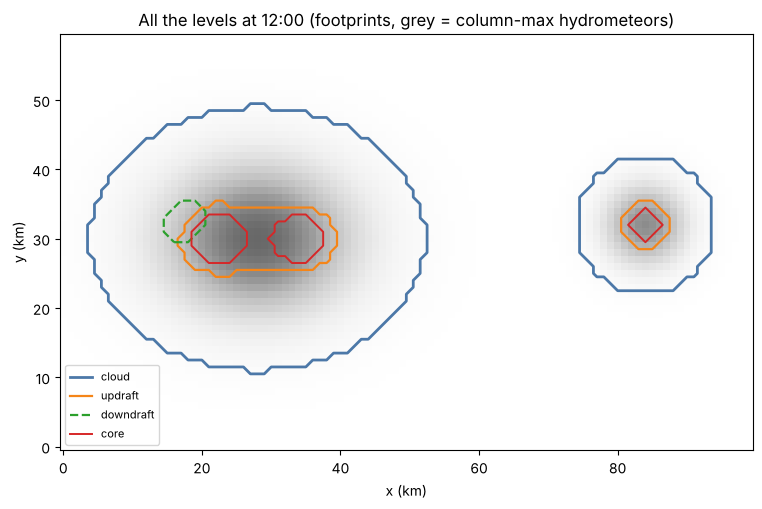

In [9]:
plot_step(frames[0], step0, title="All the levels at 12:00 (footprints, grey = column-max hydrometeors)");

## 5. What the hierarchy brings

### 5.1 Context: an object only exists inside its parent

Let us run the **same `core` rule** as a root level, without any parent, and compare.

In [10]:
flat_engine = HierarchicalTrackingEngine([TrackingLevel("core", detect_objects, parent_name=None, params=RULES["core"])])
flat_results = flat_engine.run_and_track(frames, time_values=time_values)["results_by_time"]

pd.DataFrame(
    {
        "core (hierarchical)": [len(s["levels"]["core"]) for s in results],
        "core (flat)": [len(s["levels"]["core"]) for s in flat_results],
    },
    index=pd.Index(time_values, name="time"),
)

,core (hierarchical),core (flat)
time,,
12:00,3,4
12:05,3,4
12:10,3,4
12:15,2,3
12:20,2,3
12:25,2,3
12:30,2,3
12:35,2,3


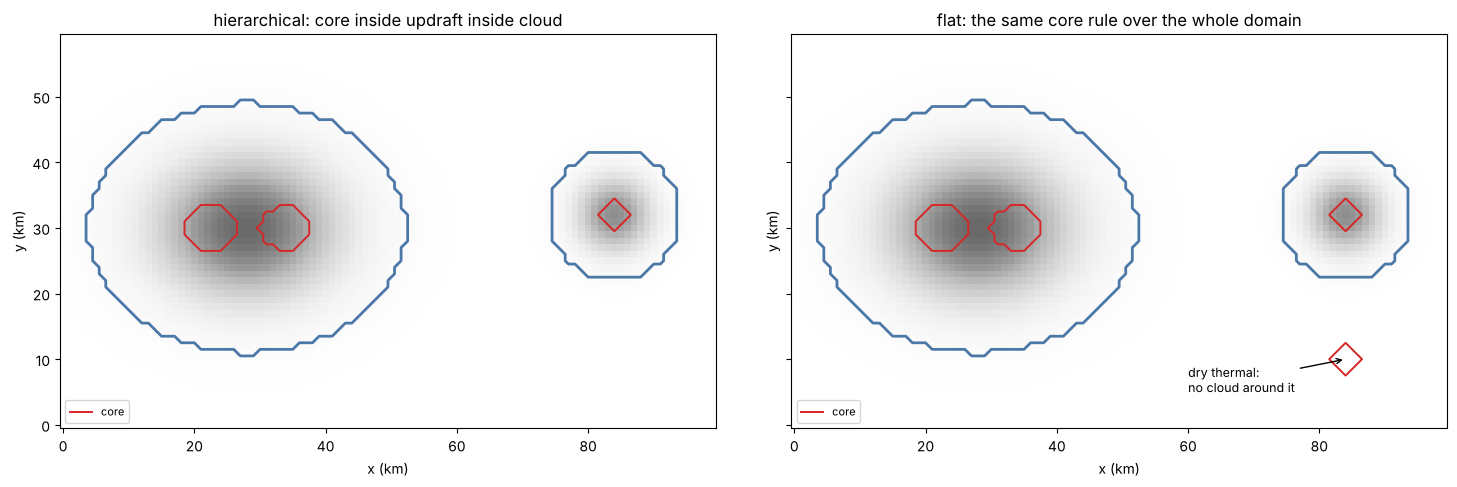

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, res, title in [(axes[0], results, "hierarchical: core inside updraft inside cloud"),
                       (axes[1], flat_results, "flat: the same core rule over the whole domain")]:
    plot_step(frames[0], {"time": time_values[0], "levels": {"core": res[0]["levels"]["core"]}}, title=title, ax=ax)
    draw_objects(ax, {"cloud": results[0]["levels"]["cloud"]}, frames[0]["W"].shape[1:])
axes[1].annotate("dry thermal:\nno cloud around it", (84, 10), (60, 5), arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.tight_layout()
plt.show()

The flat run finds one more "core": the dry thermal. Nothing in the `core` rule says that a core must be cloudy; the hierarchy says it, **without touching the rule**. In the same way, a convective core detected inside an MCS is, by construction, an MCS core.

### 5.2 Families: each object knows its parent

With `parent_object_id`, the objects of a timestep form a tree. Questions such as "how many cores in each cloud?" become a walk up or down that tree.

In [12]:
def print_family_tree(step):
    children = defaultdict(list)
    for name in level_names:
        for obj in step["levels"][name]:
            children[obj.get("parent_object_id")].append(obj)

    def show(obj, depth):
        print("    " * depth + f"{obj['level']:<10} {obj['object_id']:<22} {obj['volume_km3']:7.0f} km3")
        for child in children[obj["object_id"]]:
            show(child, depth + 1)

    for root in children[None]:
        show(root, 0)


print("--- 12:00 ---")
print_family_tree(results[0])
print("\n--- 12:20 (after the merge) ---")
print_family_tree(results[4])

--- 12:00 ---
cloud      t12:00_cloud_0001         9998 km3
    updraft    t12:00_updraft_0001        777 km3
        core       t12:00_core_0001           132 km3
        core       t12:00_core_0002           113 km3
    downdraft  t12:00_downdraft_0001       53 km3
cloud      t12:00_cloud_0002         1724 km3
    updraft    t12:00_updraft_0002         94 km3
        core       t12:00_core_0003            20 km3

--- 12:20 (after the merge) ---
cloud      t12:20_cloud_0001         9998 km3
    updraft    t12:20_updraft_0001        658 km3
        core       t12:20_core_0001           249 km3
    downdraft  t12:20_downdraft_0001       66 km3
cloud      t12:20_cloud_0002         1725 km3
    updraft    t12:20_updraft_0002         94 km3
        core       t12:20_core_0002            20 km3


In [13]:
objects_by_id = {o["object_id"]: o for step in results for name in level_names for o in step["levels"][name]}


def ancestor(obj, level_name):
    # walk up parent_object_id until the requested level
    while obj["level"] != level_name:
        obj = objects_by_id[obj["parent_object_id"]]
    return obj


cores_per_cloud = pd.DataFrame(
    [{"time": step["time"], "cloud": ancestor(core, "cloud")["object_id"]} for step in results for core in step["levels"]["core"]]
)
cores_per_cloud.groupby(["time", "cloud"]).size().rename("number of cores").to_frame().head(6)

number of cores
time  cloud                             
12:00 t12:00_cloud_0001                2
      t12:00_cloud_0002                1
12:05 t12:05_cloud_0001                2
      t12:05_cloud_0002                1
12:10 t12:10_cloud_0001                2
      t12:10_cloud_0002                1

### 5.3 Less work: a child only looks inside its parent

A child level does not scan the domain: for each parent it only examines the bounding box of that parent. The deeper the level, the smaller the volume examined.

In [14]:
domain = int(np.prod(frames[0]["W"].shape))


def bbox_voxels(obj):
    idx = obj["indices_3d"]
    return int(np.prod(idx.max(axis=0) - idx.min(axis=0) + 1))


rows = []
for lvl in levels:
    parents = [None] if lvl.parent_name is None else step0["levels"][lvl.parent_name]
    examined = domain if lvl.parent_name is None else sum(bbox_voxels(p) for p in parents)
    rows.append({"level": lvl.name, "searched in": lvl.parent_name or "whole domain",
                 "voxels examined": examined, "% of domain": round(100 * examined / domain, 1)})
pd.DataFrame(rows)

,level,searched in,voxels examined,% of domain
0,cloud,whole domain,120000,100.0
1,updraft,cloud,44357,37.0
2,downdraft,cloud,44357,37.0
3,core,updraft,3730,3.1


## 6. Tracking in time

Each tracker links the objects of its level from one timestep to the next: it shifts each track by its wind (zero here), computes the 3D IoU with the new objects, and solves the assignment with the Hungarian algorithm. An unassigned track that overlaps an object already taken is recorded as a **merge**; an unassigned object that overlaps a continued track starts a child track (**split**).

In [15]:
pd.DataFrame(
    [{"level": name, "track": tid, "start": tr["start_time"], "end": tr["end_time"], "steps": len(tr["history"]),
      "events": "; ".join(f"{e['type']} at {e['time']}" + (f" into {e['into']}" if "into" in e else "") for e in tr.get("events", []))}
     for name in level_names for tid, tr in tracks[name].items()]
)

,level,track,start,end,steps,events
0,cloud,cloud_0001,12:00,12:35,8,
1,cloud,cloud_0002,12:00,12:35,8,
2,updraft,updraft_0001,12:00,12:35,8,
3,updraft,updraft_0002,12:00,12:35,8,
4,downdraft,downdraft_0001,12:00,12:35,8,
5,core,core_0001,12:00,12:10,3,merge at 12:15 into core_0002
6,core,core_0002,12:00,12:35,8,
7,core,core_0003,12:00,12:35,8,


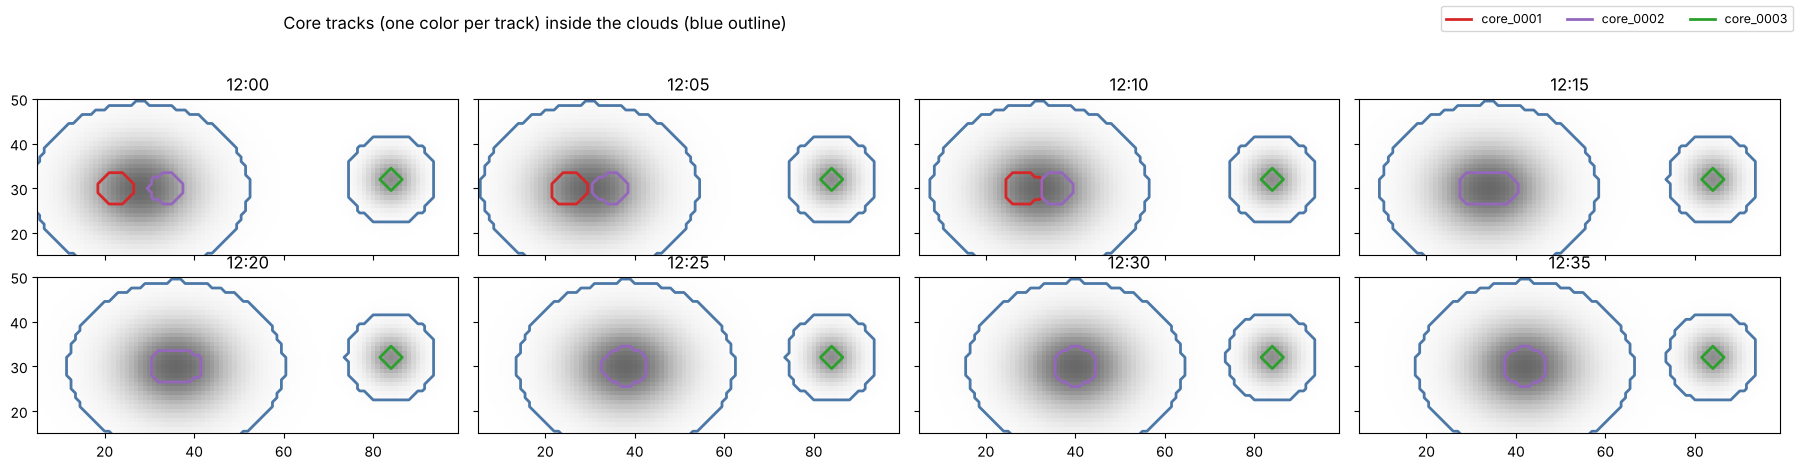

In [16]:
track_of = {obj["object_id"]: tid for name in level_names for tid, tr in tracks[name].items() for obj in tr["history"]}
core_track_ids = sorted(tracks["core"])
palette = ["#d62728", "#9467bd", "#2ca02c", "#e377c2", "#8c564b"]  # no blue: blue is the cloud outline
track_colors = {tid: palette[i % len(palette)] for i, tid in enumerate(core_track_ids)}

fig, axes = plt.subplots(2, 4, figsize=(18, 4.6), sharex=True, sharey=True)
for ax, frame, step in zip(axes.flat, frames, results):
    hydro = (frame["MRC"].values + frame["MRI"].values).max(axis=0)
    ax.imshow(hydro, origin="lower", cmap="Greys", vmin=0, vmax=1.5)
    draw_objects(ax, {"cloud": step["levels"]["cloud"]}, hydro.shape)
    for core in step["levels"]["core"]:
        tid = track_of[core["object_id"]]
        style = {"core": dict(color=track_colors[tid], lw=2.0, ls="-")}
        draw_objects(ax, {"core": [core]}, hydro.shape, styles=style)
    ax.set_title(step["time"])
    ax.set_xlim(5, 99)
    ax.set_ylim(15, 50)
fig.legend(handles=[plt.Line2D([], [], color=c, lw=2, label=t) for t, c in track_colors.items()],
           loc="upper right", ncol=len(track_colors), fontsize=9)
fig.suptitle("Core tracks (one color per track) inside the clouds (blue outline)", x=0.3)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

The two cores of cloud A keep their identity until 12:10; at 12:15 `core_0001` ends with a `merge` event into `core_0002`, which carries on alone.

### Tracks across levels

Because each object knows its parent, a track also knows its parent tracks. Below, every core track is attached to the updraft track and the cloud track that contained it during its life.

In [17]:
def parent_tracks(track, level_name):
    return sorted({track_of[ancestor(obj, level_name)["object_id"]] for obj in track["history"]})


pd.DataFrame(
    [{"core track": tid, "from": tr["start_time"], "to": tr["end_time"],
      "in updraft track": ", ".join(parent_tracks(tr, "updraft")), "in cloud track": ", ".join(parent_tracks(tr, "cloud"))}
     for tid, tr in tracks["core"].items()]
)

,core track,from,to,in updraft track,in cloud track
0,core_0001,12:00,12:10,updraft_0001,cloud_0001
1,core_0002,12:00,12:35,updraft_0001,cloud_0001
2,core_0003,12:00,12:35,updraft_0002,cloud_0002


## 7. To go further

- **Change what an object is**: edit one rule (e.g. `"value": 4.0` for the cores) and rerun; the other levels are not affected.
- **Change the family**: add a level with `parent_name=...`, or make `downdraft` a root level to search it everywhere, clouds or not.
- **Detect without tracking**: leave `tracker=None` on a level.
- **Real data**: `convective_cores_example.ipynb` does the same with a MesoNH file (MCS → cores and downdrafts).